# Curation

In this tutorial we will view and curate spike sorting results. We will first do some manual curation with the SpikeInterface-GUI, then show some automated tools for unit labeling and merging.

In [81]:
import json
import warnings
from pathlib import Path

import spikeinterface as si
import spikeinterface.curation as sc
import spikeinterface.widgets as sw

In [2]:
warnings.filterwarnings("ignore")

In [3]:
%matplotlib widget

In [4]:
si.set_global_job_kwargs(n_jobs=0.5)

In [5]:
# Modify this to where you downloaded your datasets

# Modify this to where you downloaded your datasets
home = Path.home()
base_data_folder = Path(home / "school_2026/data/")
results_folder = Path(home / "school_2026/results/")

In [6]:
analyzer_name = "full_analyzer_lupin_000939.zarr"
analyzer_folder = base_data_folder / analyzer_name

In [7]:
analyzer = si.load(analyzer_folder, load_extensions=True)
analyzer

SortingAnalyzer: 64 channels - 144 units - 1 segments - zarr - sparse
Loaded 12 extensions: amplitude_scalings, correlograms, isi_histograms, noise_levels, quality_metrics, random_spikes, spike_amplitudes, spike_locations, template_metrics, template_similarity, templates, unit_locations

## Automatic curation tools

### Threshold-based curation

This strategy for curation uses different thresholds on quality metrics. Quality metrics are designed to quantify different aspects of a unit, such as amplitude, SNR, drift, ISI violations, spike train completeness, and more.

A ful list of available quality metrics is available [here](https://spikeinterface.readthedocs.io/en/latest/modules/qualitymetrics.html).

In [51]:
qm = analyzer.get_extension("quality_metrics").get_data()
print(f"Available metrics: {qm.columns.values.to_numpy()}")

Available metrics: ['amplitude_cutoff' 'amplitude_cv_median' 'amplitude_cv_range'
 'amplitude_median' 'drift_mad' 'drift_ptp' 'drift_std' 'firing_range'
 'firing_rate' 'isi_violations_count' 'isi_violations_ratio'
 'noise_cutoff' 'noise_ratio' 'num_spikes' 'presence_ratio'
 'rp_contamination' 'rp_violations' 'sd_ratio' 'sliding_rp_violation'
 'snr' 'sync_spike_2' 'sync_spike_4' 'sync_spike_8']


`qm` is a `pandas.DataFrame` with unit ID as indices. We can easily perform a query with a quality-metric "recipe", such as:

In [52]:
qm.head()

,amplitude_cutoff,amplitude_cv_median,amplitude_cv_range,amplitude_median,drift_mad,drift_ptp,drift_std,firing_range,firing_rate,isi_violations_count,...,num_spikes,presence_ratio,rp_contamination,rp_violations,sd_ratio,sliding_rp_violation,snr,sync_spike_2,sync_spike_4,sync_spike_8
5,0.000000,0.326821,0.247052,-91.065002,0.455627,3.310486,0.675496,18.40,7.277072,674,...,91984,1.0,0.399503,428,1.382180,0.290,4.959256,0.087298,0.000337,0.000000
15,0.000077,NaN,NaN,-109.589996,0.813049,4.156006,1.110726,61.40,35.047967,4140,...,443015,1.0,0.076196,2276,1.626690,0.050,6.155241,0.110211,0.000725,0.000000
17,0.000435,NaN,NaN,-102.959999,0.686035,3.890381,0.942183,54.33,34.943539,4737,...,441695,1.0,0.086796,2563,1.303327,0.055,5.625614,0.086433,0.000401,0.000000
21,0.002113,0.260171,0.235024,-108.614998,0.497009,3.809265,0.815589,36.73,26.110485,4452,...,330043,1.0,0.158481,2515,1.430025,0.105,6.246079,0.089800,0.000382,0.000000
25,0.002844,0.279240,0.449688,-74.294998,0.627502,4.296661,0.799785,13.00,6.407707,942,...,80995,1.0,1.000000,630,1.434166,NaN,4.686245,0.089598,0.000457,0.000025


In [53]:
sc.threshold_metrics_label_units?

Signature:
sc.threshold_metrics_label_units(
    metrics: 'pd.DataFrame',
    thresholds: dict | str | pathlib._local.Path,
    pass_label: str = 'good',
    fail_label: str = 'noise',
    operator: str = 'and',
    nan_policy: str = 'fail',
    column_name: str = 'label',
)
Docstring:
Label units based on metrics and thresholds.

Parameters
----------
metrics : pd.DataFrame
    A DataFrame containing unit metrics with unit IDs as index.
thresholds : dict | str | Path
    A dictionary or JSON file path where keys are metric names and values are threshold values for labeling units.
    Each key should correspond to a quality metric present in the analyzer's quality metrics DataFrame. Values
    should contain at least "greater" and/or "less" keys to specify threshold ranges. Thresholds are inclusive, i.e.
    "greater" is >= and "less" is <=. Optionally, an "abs": True entry can be included to indicate that the metric
    should be treated as an absolute value when applying thresholds.


In [54]:
qc_thresholds = {
    "rp_contamination": {"less": 0.5},
    "presence_ratio": {"greater": 0.8},
    "amplitude_cutoff": {"less": 0.1}
}

In [55]:
threshold_df = sc.threshold_metrics_label_units(qm, thresholds=qc_thresholds, column_name="threshold_label")
threshold_df

,threshold_label
5,good
15,good
17,good
21,good
25,noise
...,...
226,good
227,good
228,good
229,good


In [56]:
threshold_df["threshold_label"].value_counts()

threshold_label
good     80
noise    64
Name: count, dtype: int64

Let's see how they look! The `SortingAnalyzer` has a convenient function to select units and propagate all extensions:

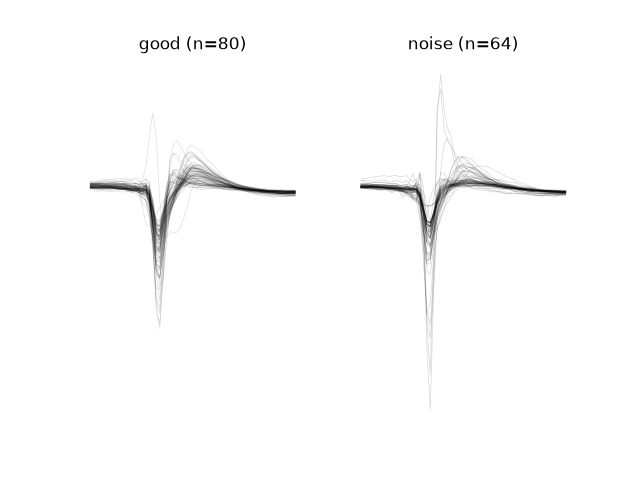

In [57]:
w = sw.plot_unit_labels(analyzer, threshold_df["threshold_label"])

**NICE!!** Most of noisy units are gone, but there are also potential good units in the noise group... maybe our curation was too strict?

### Automatic labeling

In the `curation` module we also provide some model-based automatic labeling of units. 

There are two auti-labeling tools:

* **UnitRefine**: uses pre-trained classifiers from hand-curated data from the [UnitRefine](https://www.biorxiv.org/content/10.1101/2025.03.30.645770v1) project. UniteRefine models use quality and template metrics to classify units as being `noise` or `neural` and `SUA` (single-unit activity) or `MUA` (multi-unit activity). All available models are publicly available on the [SpikeInterface HuggingFace Organization](https://huggingface.co/SpikeInterface).

* **BombCell**: uses a set of advanced heuristics based on quality and template metrics. For more information, see the [Bombcell repo](https://github.com/Julie-Fabre/bombcell)

Let's see how to use them!

For example, for the Bombcell pipeline
![image](images/bombcell_flowchart.png)

In [58]:
unitrefine_df = sc.unitrefine_label_units(
    analyzer,
    noise_neural_classifier="SpikeInterface/UnitRefine_noise_neural_classifier_lightweight",
    sua_mua_classifier="SpikeInterface/UnitRefine_sua_mua_classifier_lightweight",
)

In [59]:
unitrefine_df["unitrefine_label"].value_counts()

unitrefine_label
sua      74
mua      67
noise     3
Name: count, dtype: int64

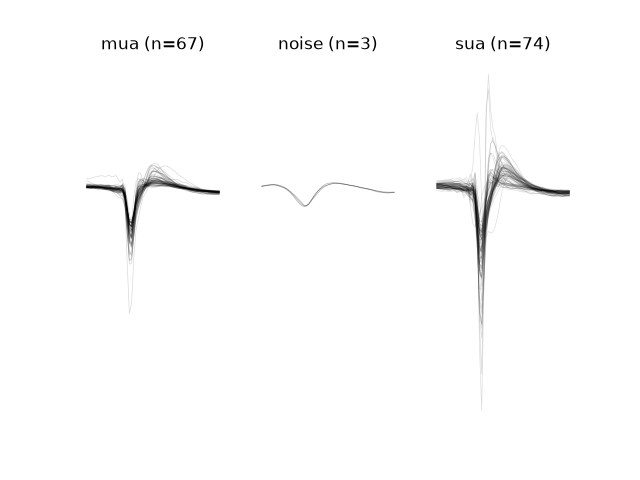

In [60]:
w = sw.plot_unit_labels(analyzer, unitrefine_df["unitrefine_label"])

In [61]:
sc.bombcell_label_units?

Signature:
sc.bombcell_label_units(
    sorting_analyzer=None,
    thresholds: dict | str | pathlib._local.Path | None = None,
    split_non_somatic: bool = False,
    external_metrics: 'pd.DataFrame | list[pd.DataFrame] | None' = None,
    label_non_somatic: bool | None = None,
    split_non_somatic_good_mua: bool | None = None,
) -> 'pd.DataFrame'
Docstring:
Label units based on quality metrics and template metrics using Bombcell logic:

1. NOISE:
    Units that fail any of the noise thresholds are labeled as "noise". The thresholds in the "noise" section
    are applied with an "AND" operator, meaning a unit must fail at least one noise metric to be labeled as
    "noise". Units that are not labeled as "noise" are then evaluated for MUA thresholds.
2. MUA:
    Units that are not "noise" but fail any of the MUA thresholds are labeled as "mua". The thresholds in the
    "mua" section are also applied with an "AND" operator, meaning a unit must fail at least one MUA metric to
    be la

In [62]:
bombcell_thresholds = sc.bombcell_get_default_thresholds()
bombcell_thresholds

{'noise': {'num_positive_peaks': {'greater': None, 'less': 2},
  'num_negative_peaks': {'greater': None, 'less': 1},
  'peak_to_trough_duration': {'greater': 0.0001, 'less': 0.00115},
  'waveform_baseline_flatness': {'greater': None, 'less': 0.5},
  'peak_after_to_trough_ratio': {'greater': None, 'less': 0.8},
  'exp_decay': {'greater': 0.01, 'less': 0.1}},
 'mua': {'amplitude_median': {'greater': 30, 'less': None, 'abs': True},
  'snr': {'greater': 5, 'less': None},
  'amplitude_cutoff': {'greater': None, 'less': 0.2},
  'num_spikes': {'greater': 300, 'less': None},
  'sliding_rp_violation': {'greater': None, 'less': 0.1},
  'presence_ratio': {'greater': 0.7, 'less': None},
  'drift_ptp': {'greater': None, 'less': 100},
  'isolation_distance': {'greater': 20, 'less': None},
  'l_ratio': {'greater': None, 'less': 0.3}},
 'non-somatic': {'peak_before_to_trough_ratio': {'greater': None, 'less': 3},
  'peak_before_width': {'greater': 0.00015, 'less': None},
  'trough_width': {'greater': 0

In [63]:
bombcell_df = sc.bombcell_label_units(
    analyzer,
    thresholds=bombcell_thresholds
)

In [64]:
bombcell_df["bombcell_label"].value_counts()

bombcell_label
mua         105
good         37
noise         1
non_soma      1
Name: count, dtype: int64

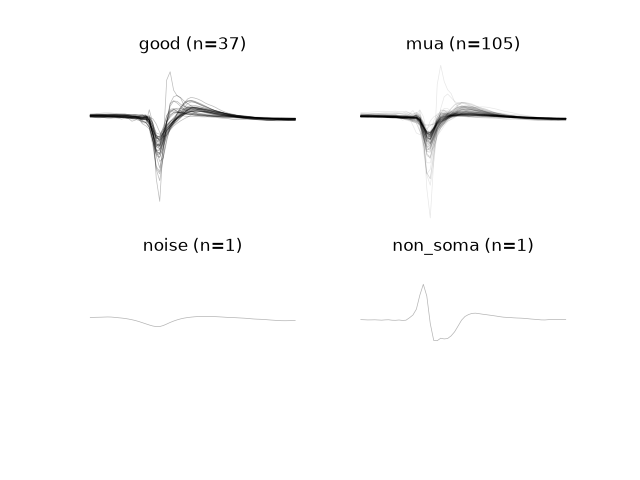

In [65]:
w = sw.plot_unit_labels(analyzer, bombcell_df["bombcell_label"])

In [66]:
# it is also convenient to store the labels in the sorting analyzer, so we can show them later in the GUI
analyzer.set_sorting_property("threshold_label", threshold_df["threshold_label"].to_numpy(dtype=str))
analyzer.set_sorting_property("unitrefine_label", unitrefine_df["unitrefine_label"].to_numpy(dtype=str))
analyzer.set_sorting_property("bombcell_label", bombcell_df["bombcell_label"].to_numpy(dtype=str))

### Auto-merging

Both quality metric-based and model-based curation provide labels for individual units. A common spike sorting mistake, however, is to *oversplit* units, i.e., multiple sorted units are actually from the same underlying neuron.

These errors are usually manually fixed with curation, but the curation module also provides some automated strategies to find potential merges. These strategies have different flavors, but usually use the similarity across templates and auto/cross correlogram shapes to make a merge decision.

See [compute_merge_unit_groups](https://spikeinterface.readthedocs.io/en/latest/api.html#spikeinterface.curation.compute_merge_unit_groups) function for documentation.

In this case, we are going to use the [SLAy](https://www.biorxiv.org/content/10.1101/2025.06.20.660590v3) method. 

![image](images/slay.png)

In [67]:
potential_merges = sc.compute_merge_unit_groups(
    analyzer,
    preset="slay",
    steps_params={"template_similarity": {"template_diff_thresh": 0.5}}
)

In [68]:
print(f"Found {len(potential_merges)} potential merges")
print(f"First potential merge: {potential_merges[0]}")

Found 9 potential merges
First potential merge: [np.int64(90), np.int64(230)]


### Curation format

We have seen that we can perform several curation actions: labeling units, removing units (usually noisy ones), and merge oversplits.

However, we haven't seen how represent and apply curation steps.
The `curation` module, for this purpose, defines a *curation format*, which is a standardized representation of the curation actions.

In this section we'll see how to formalize a curation, apply to an existing analyzer, and save it to a file that can be used by the [SpikeInterface-GUI](https://github.com/SpikeInterface/spikeinterface-gui), a powerful GUI for visualization and further curation refinement.

In [69]:
# we will use unitrefine labels as pre-computed "quality"
unitrefine_labels = analyzer.get_sorting_property("unitrefine_label").copy()
unitrefine_labels[unitrefine_labels == "sua"] = "good"
unitrefine_labels[unitrefine_labels == "mua"] = "MUA"

label_definitions = {
    "quality": dict(name="quality", label_options=["good", "MUA", "noise"], exclusive=True),
}
manual_labels = [
    {"unit_id": unit_id, "labels": {"quality": [unitrefine_labels[unit_index]]}}
    for unit_index, unit_id in enumerate(analyzer.unit_ids)
]

In [70]:
curation_dict = dict(
    format_version="2",
    unit_ids=analyzer.unit_ids,
    label_definitions=label_definitions, 
    merges=[
        dict(unit_ids=p)
        for p in potential_merges
    ],
    removed=analyzer.unit_ids[unitrefine_labels == "noise"],
    manual_labels=manual_labels
)

Now that we have a curation with all steps (remove, merge, label) we can apply it in one go!

In [71]:
from spikeinterface.curation import validate_curation_dict

In [72]:
validate_curation_dict(curation_dict)

In [73]:
# we can use the Curation for more secure serialization
from spikeinterface.curation.curation_model import Curation

curation = Curation(**curation_dict)

In [74]:
curation.model_dump().keys()

dict_keys(['supported_versions', 'format_version', 'unit_ids', 'label_definitions', 'manual_labels', 'removed', 'merges', 'splits'])

### Curation "refinement" in the SpikeInterface-GUI

Instead of the SpikeInterface-GUI for fully manual curation, we can pre-load it with the automated curation outputs to speed up the curation process. 
The GUI can be now used to review and refine the automated curation.

In [75]:
user_settings = {
    "spikeamplitude": {
        "range_type": "absolute",
        "range_min": -500,
        "range_max": 200,
    }
}

In [76]:
run_mainwindow(
    analyzer,
    displayed_unit_properties=["threshold_label", "unitrefine_label", "bombcell_label"],
    curation=True,
    curation_dict=curation.model_dump(),
    user_settings=user_settings,
    mode="desktop"
)

qt.qpa.wayland.textinput: virtual void QtWaylandClient::QWaylandTextInputv3::disableSurface(wl_surface*) Trying to disable 0x8c0e09f0 but 0x78f46e40 is focused
qt.qpa.wayland.textinput: virtual void QtWaylandClient::QWaylandTextInputv3::disableSurface(wl_surface*) Trying to disable 0x8c0e09f0 but 0x78f46e40 is focused
qt.qpa.wayland.textinput: virtual void QtWaylandClient::QWaylandTextInputv3::disableSurface(wl_surface*) Trying to disable 0x8c0e09f0 but 0x78f46e40 is focused
qt.qpa.wayland.textinput: virtual void QtWaylandClient::QWaylandTextInputv3::disableSurface(wl_surface*) Trying to disable 0x8c0e09f0 but 0x78f46e40 is focused
qt.qpa.wayland.textinput: virtual void QtWaylandClient::QWaylandTextInputv3::disableSurface(wl_surface*) Trying to disable 0x8c0e09f0 but 0x78f46e40 is focused
qt.qpa.wayland.textinput: virtual void QtWaylandClient::QWaylandTextInputv3::disableSurface(wl_surface*) Trying to disable 0x8c0e09f0 but 0x78f46e40 is focused
qt.qpa.wayland.textinput: virtual void Q

<spikeinterface_gui.backend_qt.QtMainWindow(0x7b1b4660) at 0x7e4d069a4840>

In [77]:
with open(results_folder / "refined_curation.json") as f:
    refined_curation_dict = json.load(f)

FileNotFoundError: [Errno 2] Aucun fichier ou dossier de ce nom: '/home/pierre/school_2026/results/refined_curation.json'

In [ ]:
analyzer_curated = sc.apply_curation(analyzer, refined_curation_dict, sparsity_overlap=0.5)
analyzer_curated